<h1> Two states flipping</h1>

<h3> Python code 2-05 accompanying <i>Molecular Machines</i></h3>

<p> G. Woehlke, 2025 - Mar 2026 (converted from Wolfram Mathematica, aided by A.I.)</p>

<p>Given is the following system, in which one molecule flips between two conformations:

   $S_1$ &harr; $S_2$ 
   
This might describe a protein in two conformations, or a fluorophore that can be present in a high and a low fluorescence state. The equilibrium of the states follows from forward and backward rates $c_{S1}'(t) = k_{12} \cdot c_{S1}(t)$, and  $c_{S2}'(t) = k_{21} \cdot c_{S2}(t)$:</p>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.linalg import expm

# t = sp.symbols('t')
# k12, k21 = sp.symbols('k12 k21')
t = np.linspace(0,5,400)
k12 = 1.0
k21 = 0.2


The SciPy library has a linear algebra module (scipy.linalg) that solves the system using the transition matrix **A**

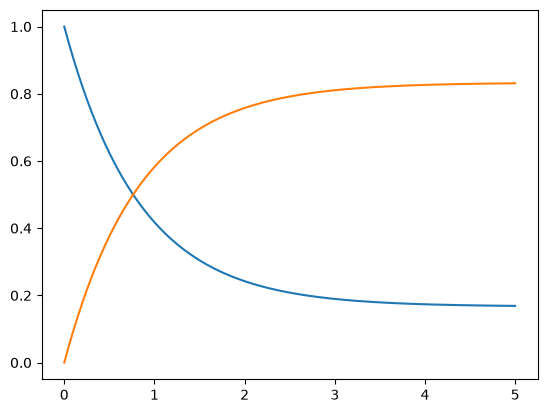

In [4]:
A = np.array([[-k12, k21],
              [k12, -k21]])

X0 = np.array([1,0])
X = np.array([expm(A*ti) @ X0 for ti in t])

plt.plot(t,X[:,0])
plt.plot(t,X[:,1])

## Interactive plot:

In [5]:
from ipywidgets import interact, FloatSlider
from scipy.linalg import expm

In [6]:
def plot_system(k12=1.0, k21=0.2):

#    t = np.linspace(0,5,400)
#    x, y = solution(t,k12,k21)

    A = np.array([[-k12, k21],
              [k12, -k21]])

    X0 = np.array([1,0])

    X = np.array([expm(A*ti) @ X0 for ti in t])

    
    plt.figure(figsize=(7,5))
#    plt.plot(t,x,color="blue",label="S1")
#    plt.plot(t,y,color="lightblue",label="S2")
    plt.plot(t,X[:,0],color="blue",label="S1")
    plt.plot(t,X[:,1],color="lightblue",label="S2")

    plt.xlabel("time / s")
    plt.ylabel("concentration")
    plt.title("Equilibrium between states S1 ⇌ S2")

    plt.text(2,0.5,f"k12 = {k12:.2f} s⁻¹\nk21 = {k21:.2f} s⁻¹")

    plt.legend()
    plt.show()

interact(plot_system,
         k12=FloatSlider(min=0,max=1,value=1,step=0.01),
         k21=FloatSlider(min=0,max=1,value=0.2,step=0.01))

interactive(children=(FloatSlider(value=1.0, description='k12', max=1.0, step=0.01), FloatSlider(value=0.2, de…

<function __main__.plot_system(k12=1.0, k21=0.2)>

<h3>Figure legend </h3>
<p>Time course of equilibrium approach.  <span style="color:lightblue">Light blue </span> curve: concentration of state 2, <span style="color:blue">blue </span> curve: concentration of state 1.</p>
<p>    Kinetic scheme:  $S_1$ &harr; $S_2$ </p>
<p>Vary forward and backward rates, and calculate $\frac{k_{21}}{k_{12}}$! What does this parameter mean?</p>